# Imports

In [88]:
import os
import numpy as np
import pandas as pd
import transformers
import tensorflow as tf
import keras
import tqdm as tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

import matplotlib.pyplot as plt
import onnx
import onnxruntime as ort
from PIL import Image
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import umap
from matplotlib.colors import BoundaryNorm
import h5py

# Data

Load and prepare your dataset. Dataset should have at least 10k samples in it. Each dataset cannot be used by more than two students.

In [2]:
labels = [
    'Among Us', 
    'Apex Legends', 
    'Fortnite', 
    'Forza Horizon', 
    'Free Fire', 
    'Genshin Impact', 
    'God of War', 
    'Minecraft', 
    'Roblox', 
    'Terraria'
]

BASE_PATH = Path('Dataset')

In [3]:
def iter_files():
    for i, label in enumerate(labels):
        for p in (BASE_PATH / label).iterdir():
            yield str(p), i

In [4]:
files_amount = sum(1 for _ in iter_files())
files_amount

10000

In [5]:
CHUNK_SIZE = 512
indices_shuffle = None
with h5py.File('dataset.h5', 'a') as f:
    y = np.array(list(l for _, l in iter_files()), dtype=np.int32)

    indices_shuffle = np.arange(y.shape[0])
    idx_train, idx_val = train_test_split(
        indices_shuffle,
        test_size=0.1,
        shuffle=True,
        stratify=y,
        random_state=1
    )

    labels_train = f.create_dataset(
        'labels_train',
        shape=(len(idx_train),),
        dtype=np.int32,
        chunks=(CHUNK_SIZE,)
    )

    labels_val = f.create_dataset(
        'labels_val',
        shape=(len(idx_val),),
        dtype=np.int32,
        chunks=(CHUNK_SIZE,)
    )

    labels_train[:] = y[idx_train]
    labels_val[:] = y[idx_val]
    del y

    paths = np.array(list(p for p, _ in iter_files()))
    paths_train = f.create_dataset(
        'paths_train',
        shape=(len(idx_train),),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks=(CHUNK_SIZE,)
    )

    paths_val = f.create_dataset(
        'paths_val',
        shape=(len(idx_val),),
        dtype=h5py.string_dtype(encoding='utf-8'),
        chunks=(CHUNK_SIZE,)
    )

    paths_train[:] = paths[idx_train]
    paths_val[:] = paths[idx_val]

    del paths



In [6]:
with h5py.File('dataset.h5', 'r') as f:
    print(f['paths_train'].chunks)

(512,)


In [7]:
class Dataset(keras.utils.PyDataset):
    def __init__(self,embeddings, lbls, batch_size, shuffle_num_chunks=5, seed=1, shuffle=True, **kwargs):
        super().__init__(**kwargs)

        self.X = embeddings
        self.y = lbls
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)

        self.chunk_size = self.X.chunks[0]
        self.block_size = self.chunk_size * shuffle_num_chunks
        self.n = self.X.shape[0]

        self.block_start = 0
        self.block_end = 0
        self.X_loc = None
        self.y_loc = None
        self.indexes = None

    def __len__(self):
        return -(-self.n // self.batch_size)

    def __getitem__(self, idx):
        global_start = idx * self.batch_size

        block_id = global_start // self.block_size

        block_start = block_id * self.block_size
        block_end = min(block_start + self.block_size, self.n)

        if (self.X_loc is None or self.block_start != block_start):
            self.block_start = block_start
            self.block_end = block_end

            self.X_loc = self.X[block_start:block_end]
            self.y_loc = self.y[block_start:block_end]

            self.indexes = np.arange(len(self.X_loc))

            if self.shuffle:
                self.rng.shuffle(self.indexes)

        local_start = global_start - block_start
        local_end = min(
            local_start + self.batch_size,
            len(self.indexes)
        )

        ind = self.indexes[local_start:local_end]

        batch_X = self.X_loc[ind].astype(np.float32)
        batch_y = self.y_loc[ind].astype(np.int32)

        return batch_X, batch_y

    def on_epoch_end(self):
        self.X_loc = None
        self.y_loc = None
        self.indexes = None

        self.block_start = 0
        self.block_end = 0

# Backbone

Load pretrained model from Hugging Face (or some other model repository if it's more convenient). Model should be trained on Feature Extraction task.

In [8]:
model_path = "dinov2_VITB_14.onnx"

options = ort.SessionOptions()

options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

options.intra_op_num_threads = 8
options.inter_op_num_threads = 1

session = ort.InferenceSession(
    model_path,
    sess_options=options,
    providers=["CPUExecutionProvider"]
)

In [9]:
for inp in session.get_inputs():
    print(inp.name, inp.shape, inp.type)

for out in session.get_outputs():
    print(out.name, out.shape, out.type)

pixel_values ['batch_size', 'num_channels', 'height', 'width'] tensor(float)
last_hidden_state ['batch_size', 'floor(height/14)*floor(width/14) + 1', 768] tensor(float)


In [10]:
processor = transformers.AutoImageProcessor.from_pretrained(
    "facebook/dinov2-base",
    size={"height": 350, "width": 630},
    crop_size={"height": 350, "width": 630}
)

def preprocess_image(img_path):
    img = []
    for p in img_path:
        img.append(Image.open(p).convert("RGB"))

    return processor(
        images=img,
        return_tensors="np"
    )

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


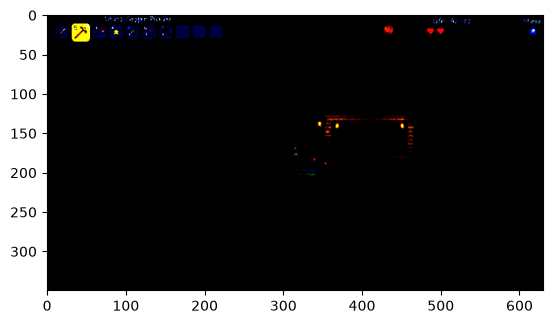

In [11]:
with h5py.File('dataset.h5', 'r') as f:
    paths_ds = f['paths_train']
    img = preprocess_image(paths_ds.asstr()[5:10])['pixel_values']
    plt.imshow(np.transpose(img[0], (1, 2, 0)))

# Feature extraction

Since we will not be training the backbone, extract features from your dataset.

Run the backbone on the images and save the extracted features. Don't forget to process the images. Images don't have to be of the same size, though it would be faster if they were. If the images don't fit in memory, lazily load them from disk

In [12]:
def get_embeddings(paths, session):
    imgs = preprocess_image(paths)

    return session.run(
        ['last_hidden_state'],
        imgs
    )[0][:, 0, :]

In [ ]:
# emb = np.empty((len(X), 768))

# b_size = 10
# for i in tqdm.tqdm(range(0, len(X), b_size)):
#     emb[i:i + b_size] = get_embeddings(X[i:i + b_size], session)
    
# np.save('embeddings.npy', emb)

# emb = np.load('embeddings.npy')

In [ ]:
BATCH_SIZE = 10

with h5py.File('dataset.h5', 'r+') as f:
    paths_train = f['paths_train']
    emb_ds = f.create_dataset(
        'embeddings_train',
        shape=(paths_train.shape[0], 768),
        dtype=np.float32,
        chunks=(CHUNK_SIZE, 768)
    )
    for i in range(0, paths_train.shape[0], BATCH_SIZE):
        paths = paths_train.asstr()[i:i + BATCH_SIZE]
        embeddings = get_embeddings(paths, session)
        emb_ds[i:i + len(embeddings)] = embeddings

    paths_val = f['paths_val']
    emb_ds = f.create_dataset(
        'embeddings_val',
        shape=(paths_val.shape[0], 768),
        dtype=np.float32,
        chunks=(CHUNK_SIZE, 768)
    )
    for i in range(0, paths_val.shape[0], BATCH_SIZE):
        paths = paths_val.asstr()[i:i + BATCH_SIZE]
        embeddings = get_embeddings(paths, session)
        emb_ds[i:i + len(embeddings)] = embeddings

In [ ]:
# with h5py.File('dataset.h5', 'r+') as f:
#     e = np.load('embeddings.npy')
#     f['embeddings_train'][:] = e[idx_train]
#     f['embeddings_val'][:] = e[idx_val]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0357141..2.2535014].


dist from 0 to 1:    0.2265416383743286
dist from 0 to 2:    0.6684120893478394
dist from 1 to 2:    0.3612564504146576


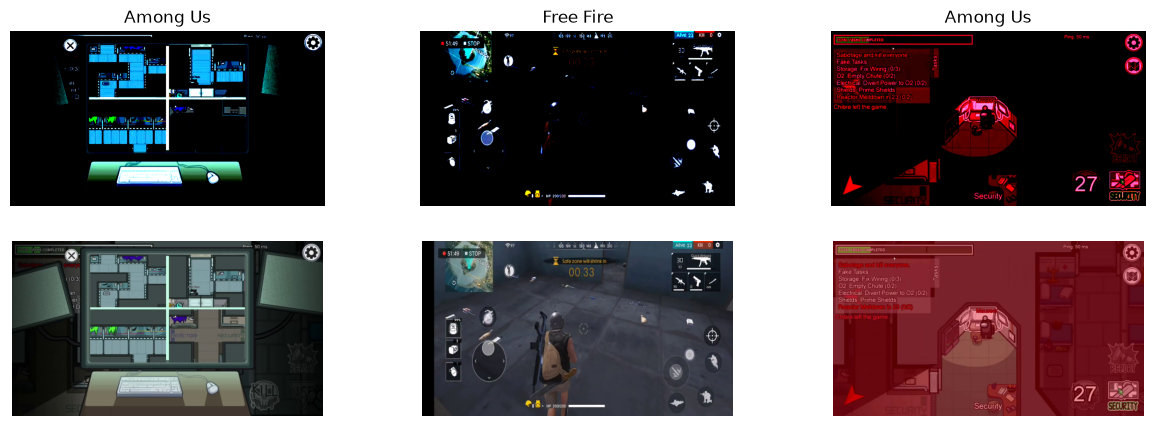

In [16]:
idxs = [13, 14, 15]

with h5py.File('dataset.h5', 'r') as f:
    paths_ds = f['paths_train']
    lbl_ds = f['labels_train']
    emb = f['embeddings_train']

    imgs = preprocess_image(paths_ds.asstr()[idxs])['pixel_values']
    fig, axes = plt.subplots(2, len(idxs), figsize=(15, 5))

    for i in range(len(idxs)):
        axes[0, i].set_title(labels[lbl_ds[idxs[i]]])
        axes[0, i].imshow(np.transpose(imgs[i], (1, 2, 0)))
        axes[0, i].axis('off')
        axes[1, i].imshow(Image.open(paths_ds.asstr()[idxs[i]]).convert('RGB'))
        axes[1, i].axis('off')

    for i, j in [(0, 1), (0, 2), (1, 2)]:
        e1 = emb[idxs[i]] / np.linalg.norm(emb[idxs[i]])
        e2 = emb[idxs[j]] / np.linalg.norm(emb[idxs[j]])

        print(f'dist from {i} to {j}:    {np.sum(e1 * e2)}')

# Prepare train/test data

Prepare `tf.data.Dataset` or some other way for the data to be used during training.

In [17]:
f = h5py.File('dataset.h5', 'r')
train_dataset = Dataset(f['embeddings_train'], f['labels_train'], 128, 4)
val_dataset = Dataset(f['embeddings_val'], f['labels_val'], 128, 4, shuffle=False)

# Build the model

Build a simple model. The model should accept an extracted feature vector and return a vector of class logits (or probabilities). Model should only have a couple (or even 1) layers with weights.

In [18]:
@keras.saving.register_keras_serializable()
class SparseCategoricalAUC(keras.metrics.AUC):
    def __init__(self, num_classes=10, **kwargs):
        super().__init__(
            multi_label=True,
            num_labels=num_classes,
            **kwargs
        )
        self.num_classes = num_classes

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = keras.ops.one_hot(
            keras.ops.cast(y_true, 'int32'),
            self.num_classes
        )

        return super().update_state(
            y_true,
            y_pred,
            sample_weight
        )

    def get_config(self):
        config = super().get_config()
        config.update({'num_classes': self.num_classes})
        return config

In [19]:
def get_model(embed_size, n_classes, dense_size, dropout=0.2):
    inputs = x = keras.layers.Input((embed_size,))
    x = keras.layers.Dense(dense_size)(x)
    x = keras.activations.gelu(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = x = keras.layers.Dense(n_classes)(x)

    return keras.Model(inputs, outputs)


Compile the model. Choose loss and metrics.

In [20]:
EPOCHS = 10

In [21]:
model = get_model(f['embeddings_train'].shape[1], 10, 1024)

model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy', SparseCategoricalAUC(name='AUC', num_classes=10)]
)

In [22]:
def make_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=f'{name}.keras',
            monitor='val_AUC',
            mode='max',
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor='val_AUC',
            patience=5,
            mode='max',
            restore_best_weights=True,
            verbose=1
        )
    ]

# Train the model

In [23]:
model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=make_callbacks('model'))
# model = keras.models.load_model('model.keras')

Epoch 1/10


I0000 00:00:1795758037.590934  193622 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - AUC: 0.8592 - accuracy: 0.9439 - loss: 0.1870
Epoch 1: val_AUC improved from None to 0.87080, saving model to model.keras

Epoch 1: finished saving model to model.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - AUC: 0.8592 - accuracy: 0.9439 - loss: 0.1870 - val_AUC: 0.8708 - val_accuracy: 0.9930 - val_loss: 0.0214
Epoch 2/10
70/71 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - AUC: 0.8783 - accuracy: 0.9955 - loss: 0.0162
Epoch 2: val_AUC improved from 0.87080 to 0.88013, saving model to model.keras

Epoch 2: finished saving model to model.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - AUC: 0.8783 - accuracy: 0.9956 - loss: 0.0160 - val_AUC: 0.8801 - val_accuracy: 0.9970 - val_loss: 0.0149
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - AUC: 0.8781 - accuracy: 0.9978 - loss: 0.0096
Epoch 3: val_AUC did not improve from 0.88013
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - AUC: 0.8781 - accuracy: 0.9978 - loss: 0.0096 - val_AUC: 0.8714 - val_accuracy: 0

# Evaluation

Evalute the model on test data.

In [24]:
model.evaluate(val_dataset)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - AUC: 0.8801 - accuracy: 0.9970 - loss: 0.0149 


[0.01490989699959755, 0.996999979019165, 0.8801255226135254]

Plot confusion matrix.

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


([<matplotlib.axis.YTick at 0x7f66a7ea6c10>,
 [Text(0, 0, 'Among Us'),
  Text(0, 1, 'Apex Legends'),
  Text(0, 2, 'Fortnite'),
  Text(0, 3, 'Forza Horizon'),
  Text(0, 4, 'Free Fire'),
  Text(0, 5, 'Genshin Impact'),
  Text(0, 6, 'God of War'),
  Text(0, 7, 'Minecraft'),
  Text(0, 8, 'Roblox'),
  Text(0, 9, 'Terraria')])

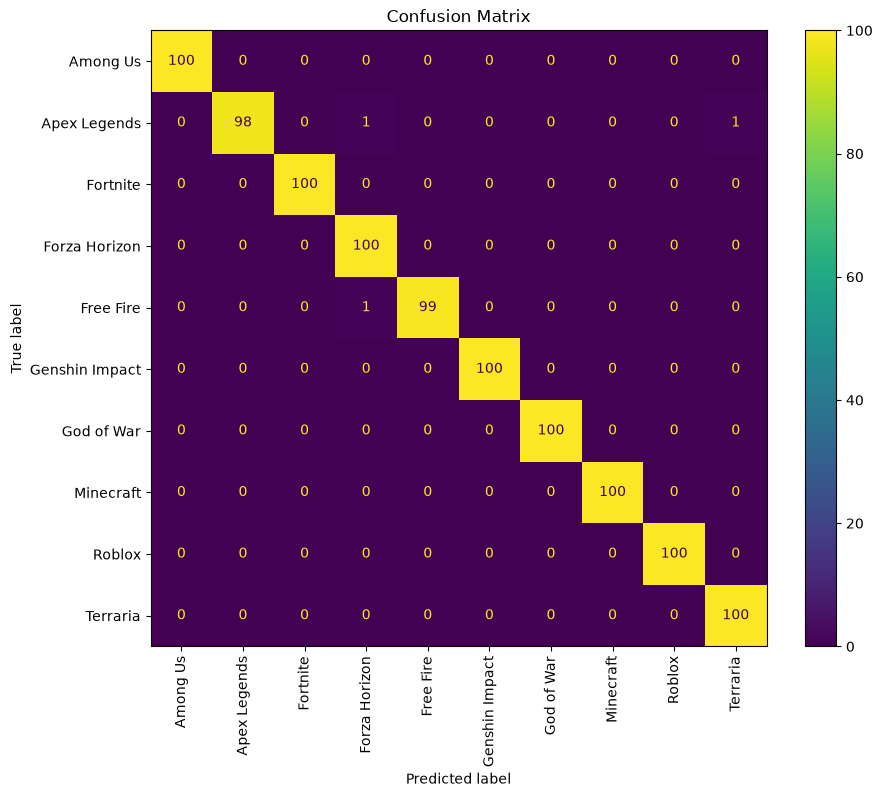

In [25]:
y_pred = np.argmax(model.predict(val_dataset), axis=-1)
conf_mat = confusion_matrix(f['labels_val'], y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax)

plt.title("Confusion Matrix")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


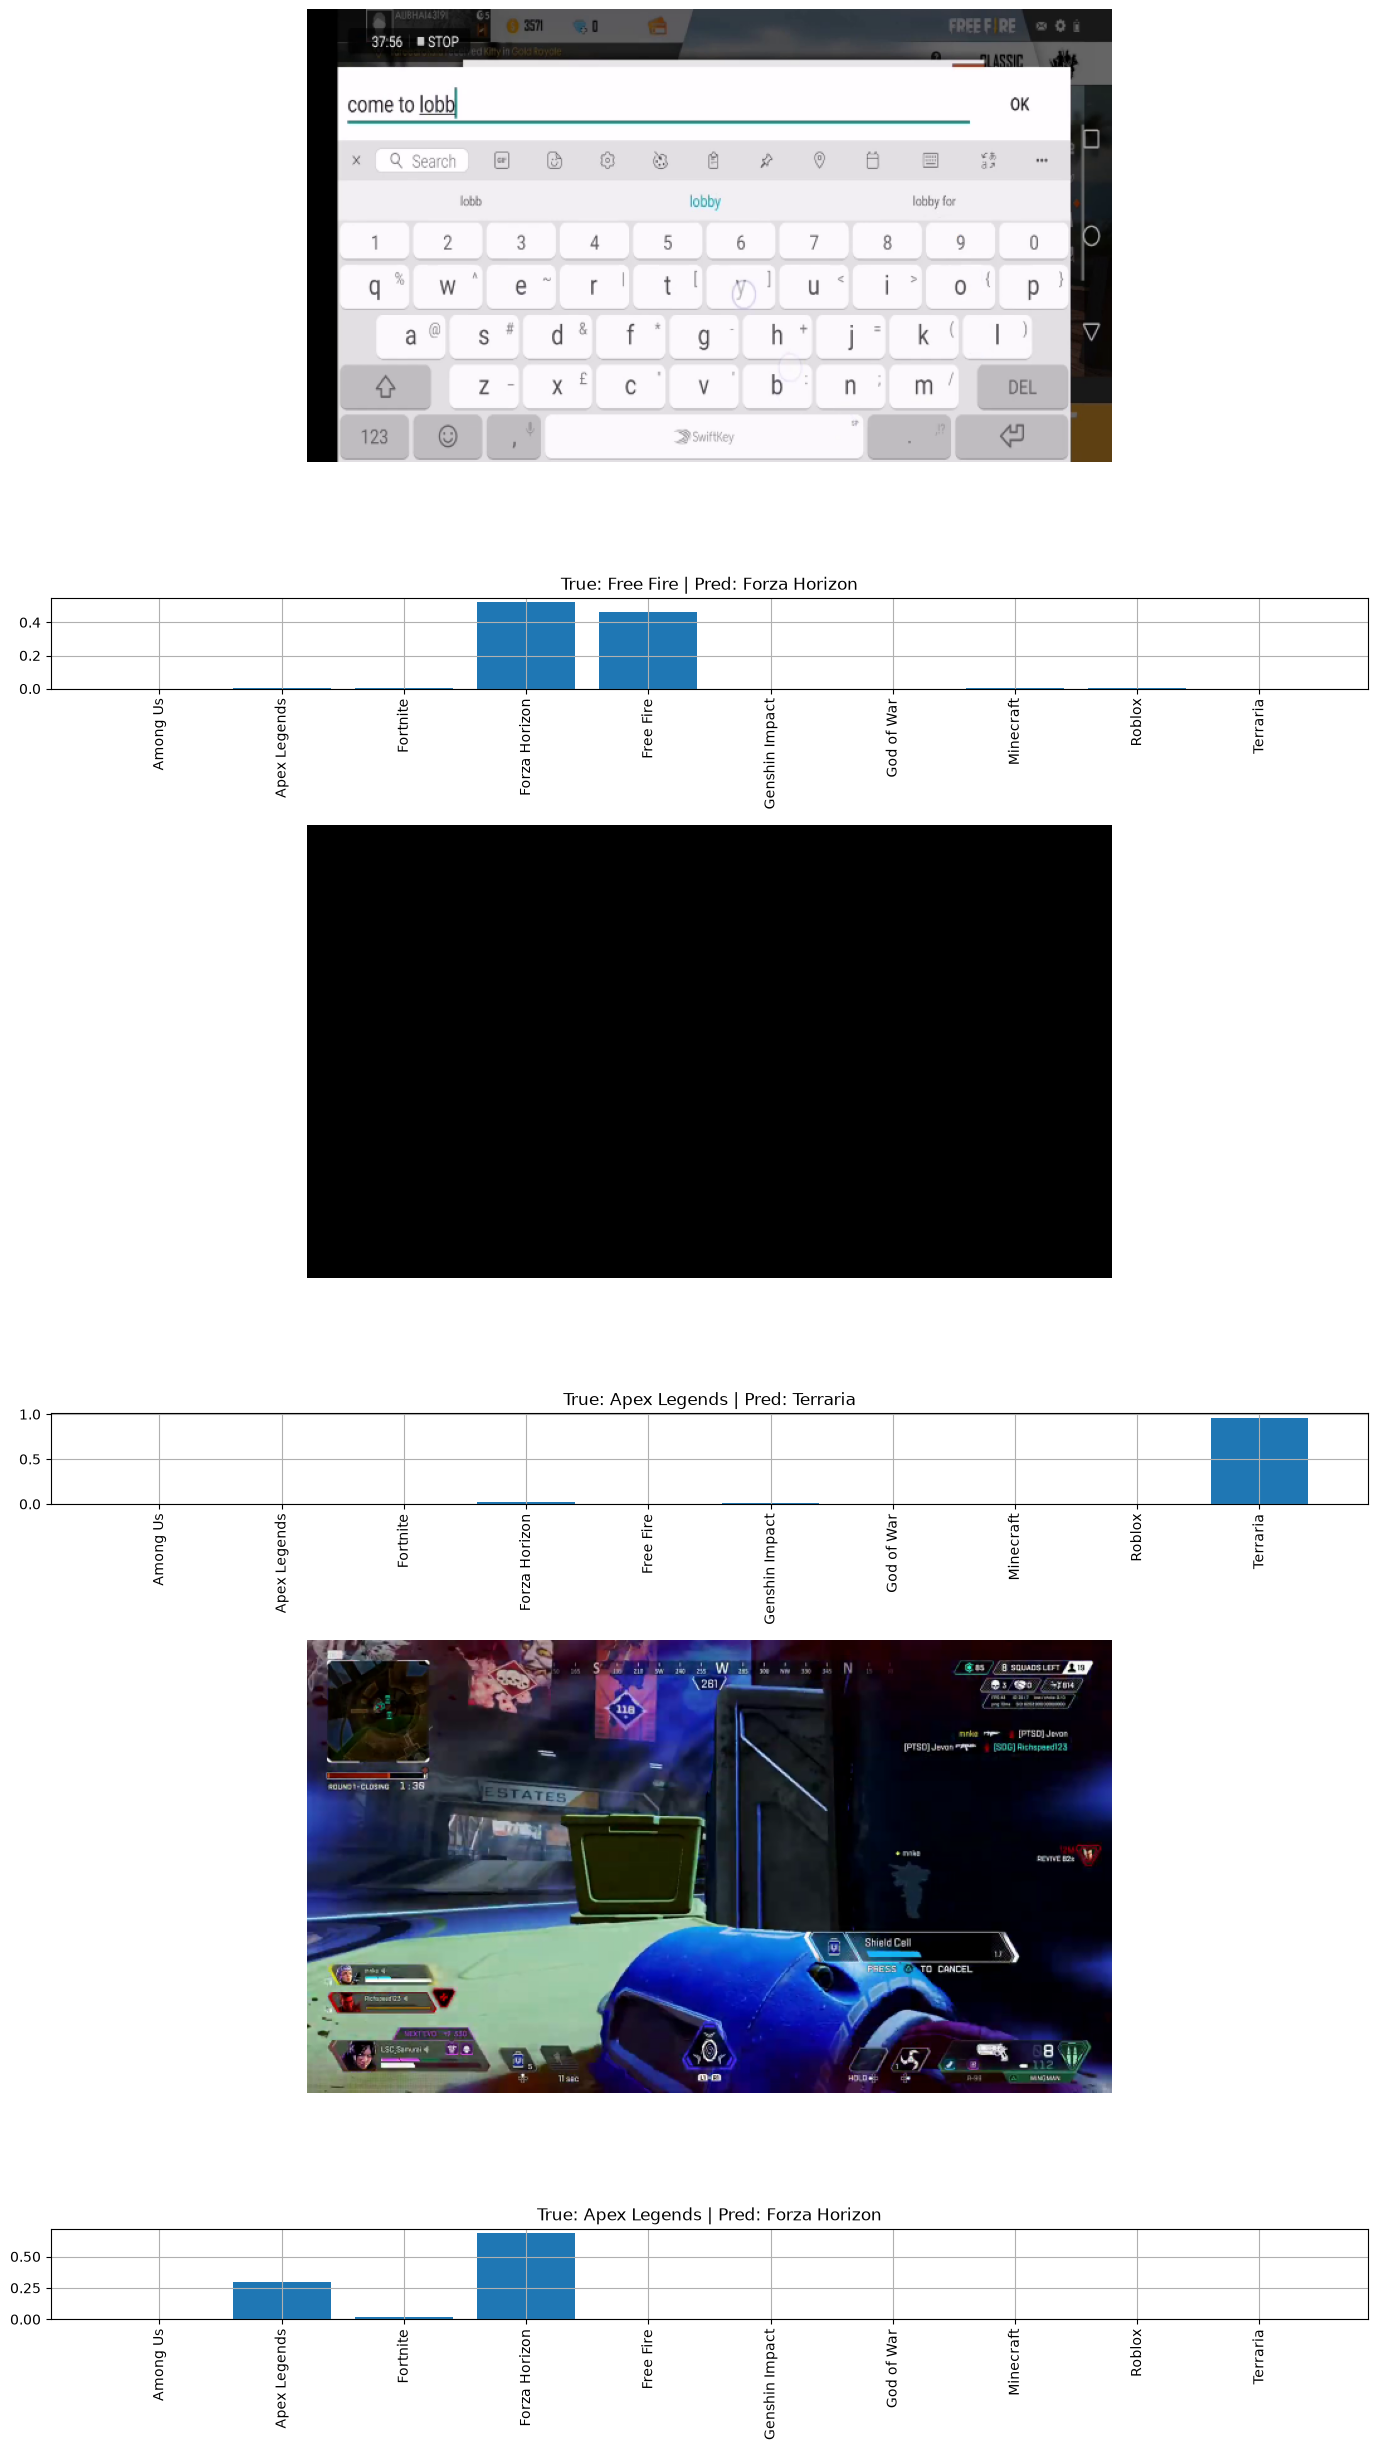

In [42]:
lim = 10
errors = np.where(f['labels_val'][:] != y_pred)[0][:lim]

imgs = [
    Image.open(f['paths_val'][i]).convert('RGB')
    for i in errors
]

imgs_pred = keras.ops.softmax(
    model.predict(f['embeddings_val'][errors]),
    axis=1
)

fig = plt.figure(figsize=(17, 10 * errors.shape[0]))

gs = fig.add_gridspec(
    2 * len(errors),
    1,
    height_ratios=[5, 1] * len(errors),
    hspace=0.5
)

for i in range(len(errors)):
    ax_img = fig.add_subplot(gs[2 * i])
    ax_bar = fig.add_subplot(gs[2 * i + 1])

    ax_img.imshow(imgs[i])
    ax_img.axis('off')

    ax_bar.bar(range(10), imgs_pred[i])
    ax_bar.set_xticks(range(10), labels, rotation=90)

    ax_bar.set_title(f"True: {labels[f['labels_val'][errors[i]]]} | Pred: {labels[y_pred[errors[i]]]}")
    ax_bar.grid()

Perform dimensiality reduction and plot the extracted features. Do classes form clusters?

In [44]:
emb = np.concatenate([f['embeddings_train'], f['embeddings_val']], axis=0)

emb_mean = np.mean(emb, axis=0)
emb_var = np.var(emb, axis=0)

In [45]:
emb_scaler = StandardScaler()
emb_scaled = emb_scaler.fit_transform(emb)

reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.2,
    n_components=2,
    compatibility_layout=False
)
emb_umap = reducer.fit_transform(emb_scaled)

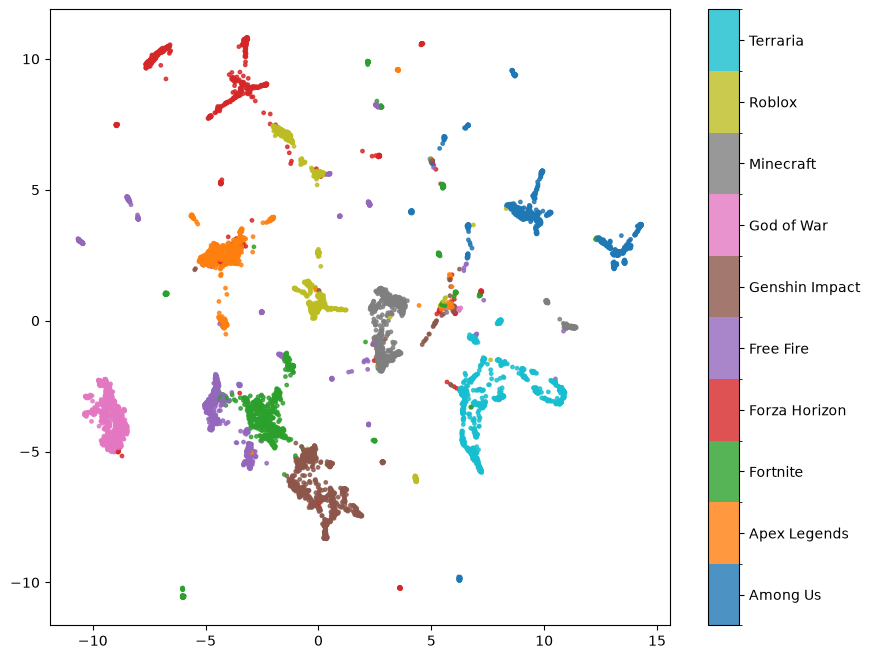

In [46]:
plt.figure(figsize=(10, 8))

bounds = np.arange(-0.5, len(labels), 1.0)
cmap = plt.get_cmap('tab10', len(labels))
norm = BoundaryNorm(bounds, ncolors=cmap.N)

sc = plt.scatter(
    emb_umap[:, 0],
    emb_umap[:, 1],
    c=np.concatenate([f['labels_train'], f['labels_val']], axis=0),
    s=6,
    alpha=0.8,
    cmap=cmap,
    norm=norm,
)

cbar = plt.colorbar(sc, ticks=np.arange(len(labels)))
cbar.set_ticklabels(labels)

# Bonus

Check if the feature extractor model can be used without a classifier layer (how large is the average feature vector similarity inbetween same in different classes)

In [73]:
emb = np.concatenate([f['embeddings_train'][:], f['embeddings_val'][:]], axis=0)

emb_normalized = emb / np.linalg.norm(emb, axis=1).reshape(-1, 1)
emb_labels = np.concatenate([f['labels_train'][:], f['labels_val'][:]], axis=0)

In [78]:
cos_by_classes = np.empty((len(labels), len(labels), 1000 * 1000))

for i in range(len(labels)):
    for j in range(len(labels)):
        cos_by_classes[i, j] = (emb_normalized[emb_labels == i] @ emb_normalized[emb_labels == j].T).ravel()

cos_by_classes_avg = np.mean(cos_by_classes, axis=-1)

Text(0, 0.5, '')

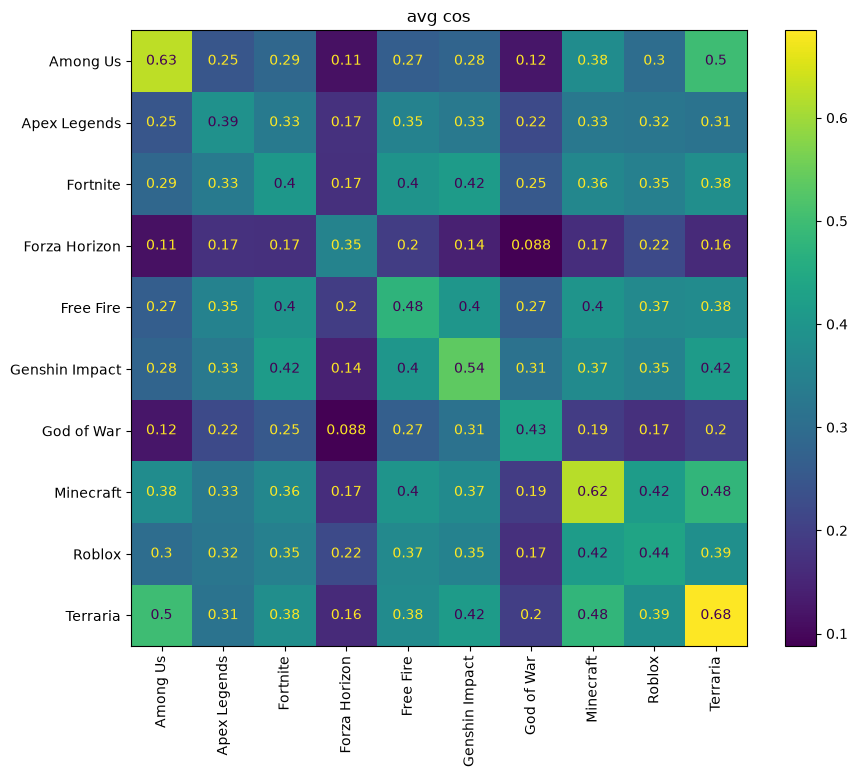

In [79]:
fig, axes = plt.subplots(1, 1, figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cos_by_classes_avg,
    display_labels=labels,
)

disp.plot(
    ax=axes,
    colorbar=True,
    xticks_rotation=90,
)
axes.set_title('avg cos')
axes.set_xlabel('')
axes.set_ylabel('')

In [80]:
label2num_classes = {
    'Among Us': 2,
    'Apex Legends': 1, 
    'Fortnite': 1, 
    # 'Forza Horizon': 2, 
    'Forza Horizon': 1,
    # 'Free Fire': 2, 
    'Free Fire': 1, 
    'Genshin Impact': 1, 
    'God of War': 1, 
    'Minecraft': 1, 
    'Roblox': 2, 
    'Terraria': 1
}

In [81]:
km = {}
for i, (k, v) in enumerate(label2num_classes.items()):
    if v > 1:
        km[k] = KMeans(
            n_clusters=v,
            init='k-means++',
            n_init=20
        )

        km[k].fit(f['embeddings_train'][f['labels_train'][:] == i])

In [82]:
km['Among Us'].cluster_centers_

array([[ 1.8119053,  1.6888999,  1.0137913, ..., -0.883968 , -1.639636 ,
         1.1095558],
       [ 3.2731986,  1.7029124,  2.4446888, ..., -1.5428188, -0.8331491,
         1.0176891]], shape=(2, 768), dtype=float32)

In [83]:
centroids = {}
for i, (k, v) in enumerate(label2num_classes.items()):
    if v == 1:
        centroids[k] = np.mean(f['embeddings_train'][f['labels_train'][:] == i], axis=0)[None]
    else:
        centroids[k] = km[k].cluster_centers_

In [84]:
centroids_2d = {}

for k, v in centroids.items():
    e = emb_scaler.transform(v)
    centroids_2d[k] = reducer.transform(e)

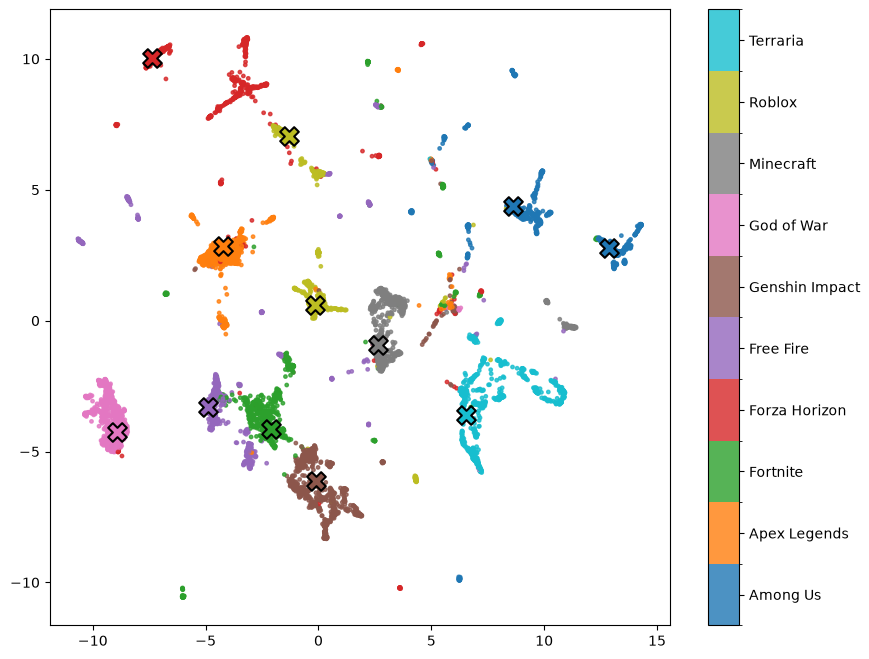

In [85]:
plt.figure(figsize=(10, 8))

bounds = np.arange(-0.5, len(labels), 1.0)
cmap = plt.get_cmap('tab10', len(labels))
norm = BoundaryNorm(bounds, ncolors=cmap.N)

sc = plt.scatter(
    emb_umap[:, 0],
    emb_umap[:, 1],
    c=np.concatenate([f['labels_train'], f['labels_val']], axis=0),
    s=6,
    alpha=0.8,
    cmap=cmap,
    norm=norm,
)

cbar = plt.colorbar(sc, ticks=np.arange(len(labels)))
cbar.set_ticklabels(labels)

for k, v in centroids_2d.items():
    plt.scatter(
        v[:, 0],
        v[:, 1],
        marker='X',
        s=180,
        edgecolors='black',
        linewidths=1.5,
        label=k
    )

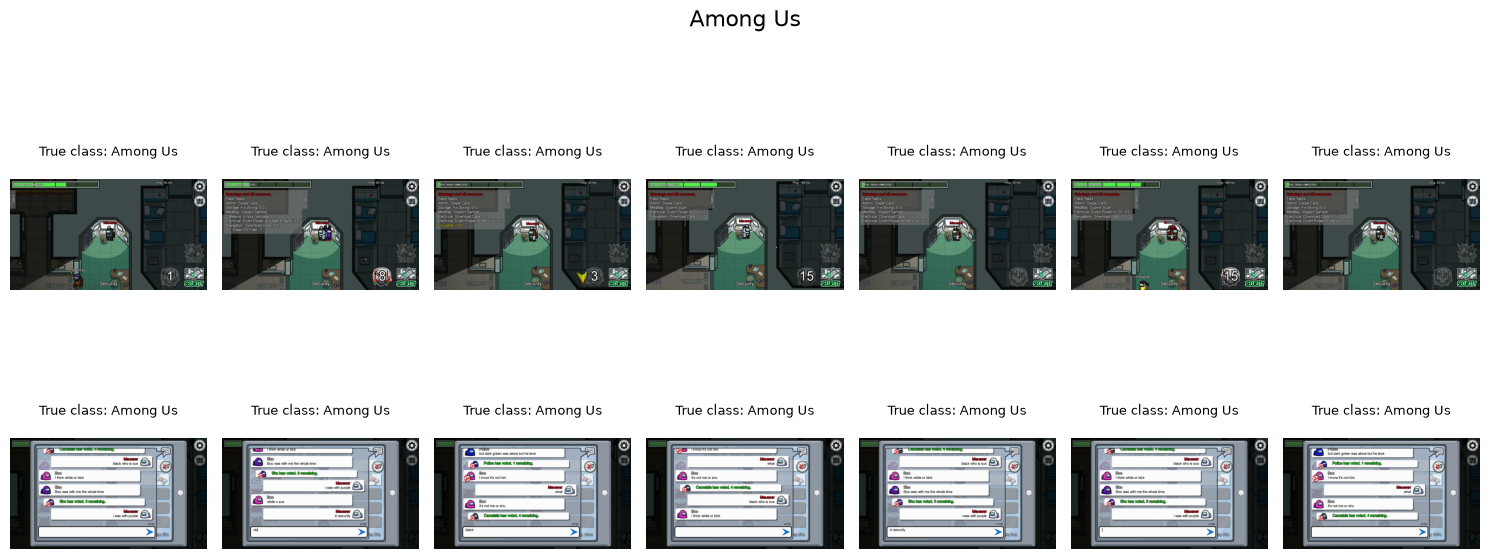

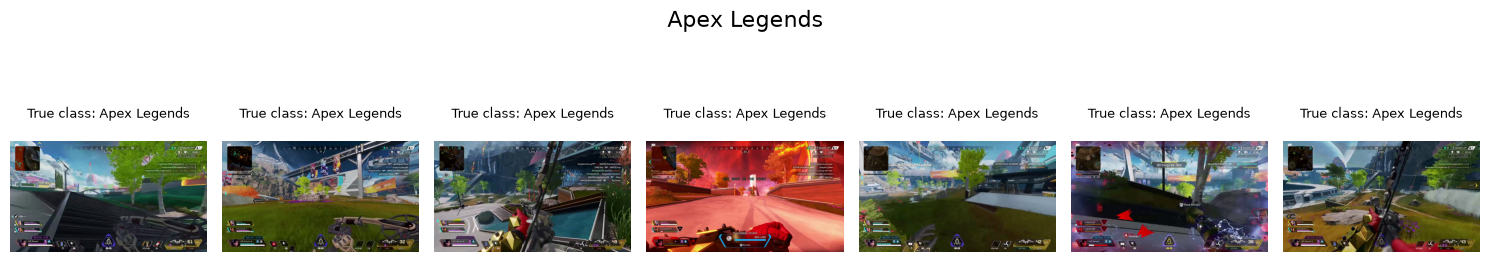

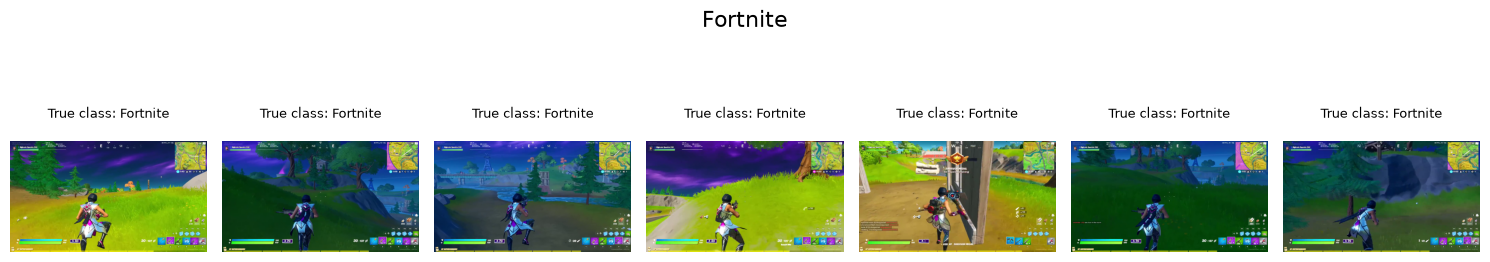

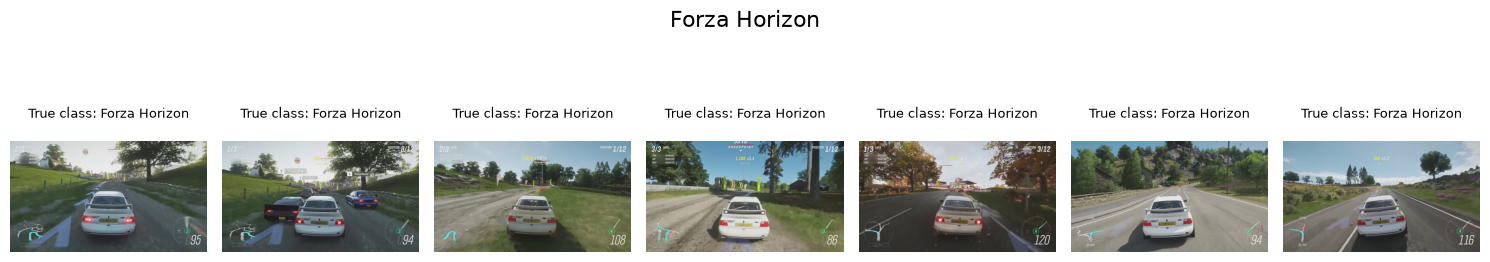

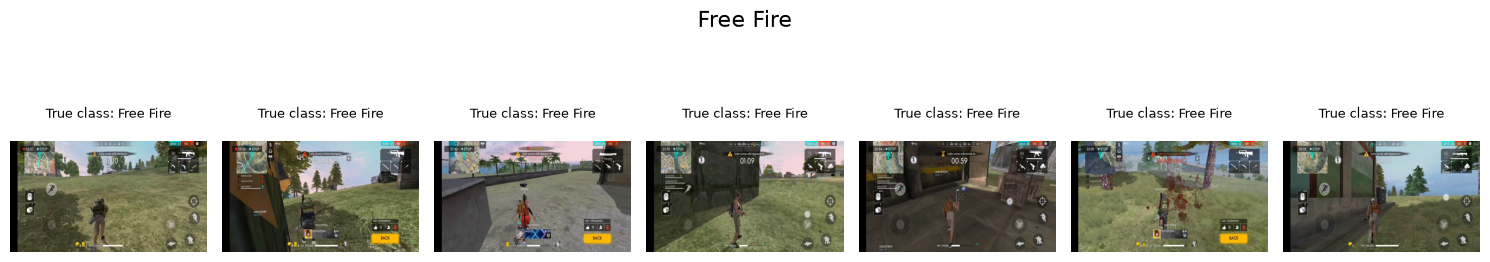

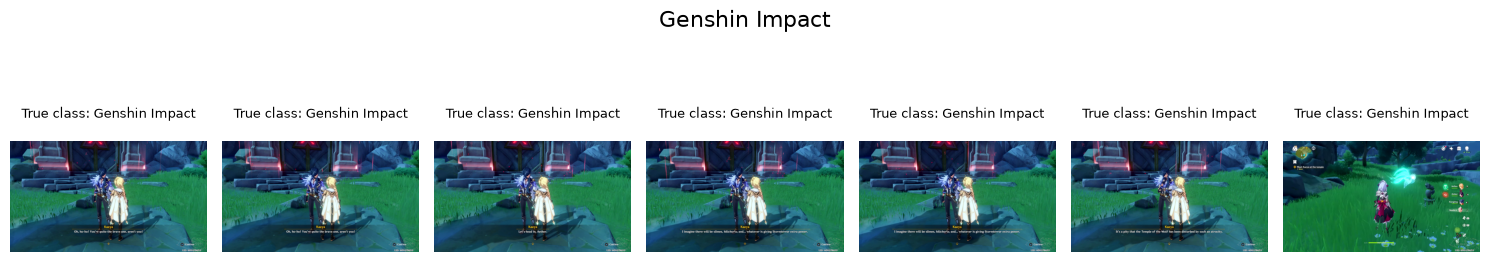

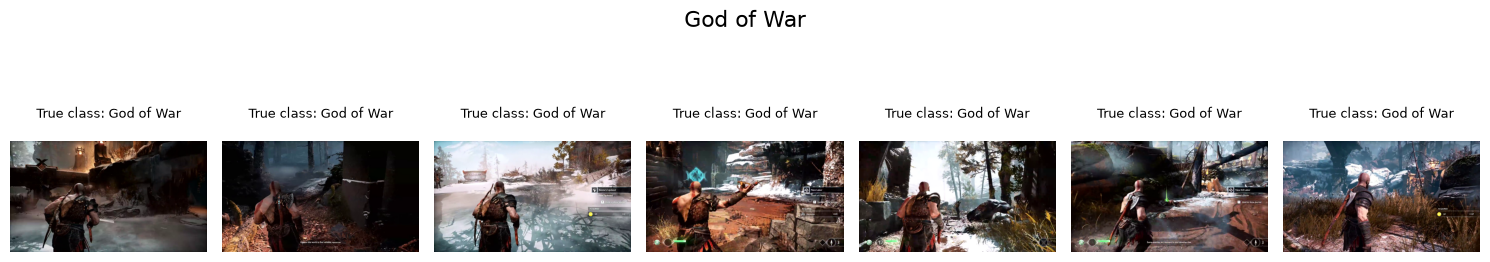

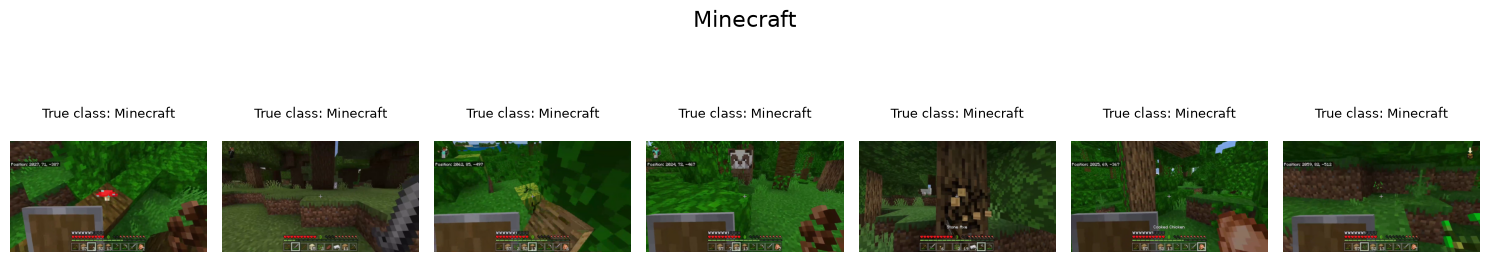

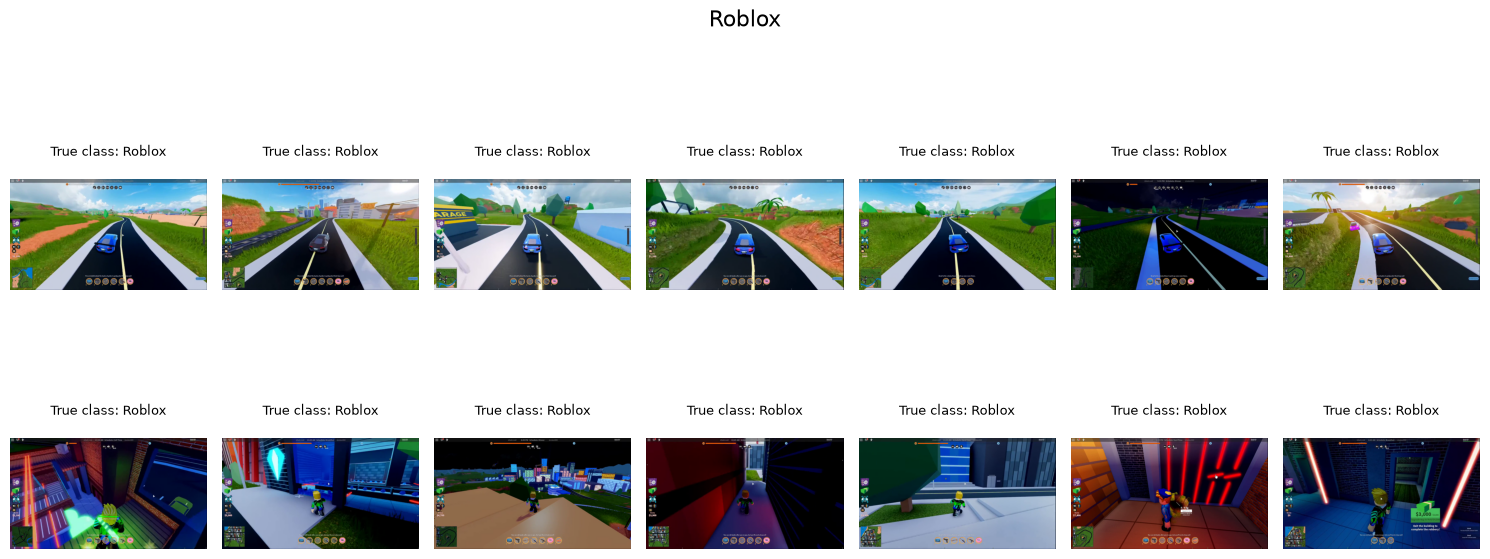

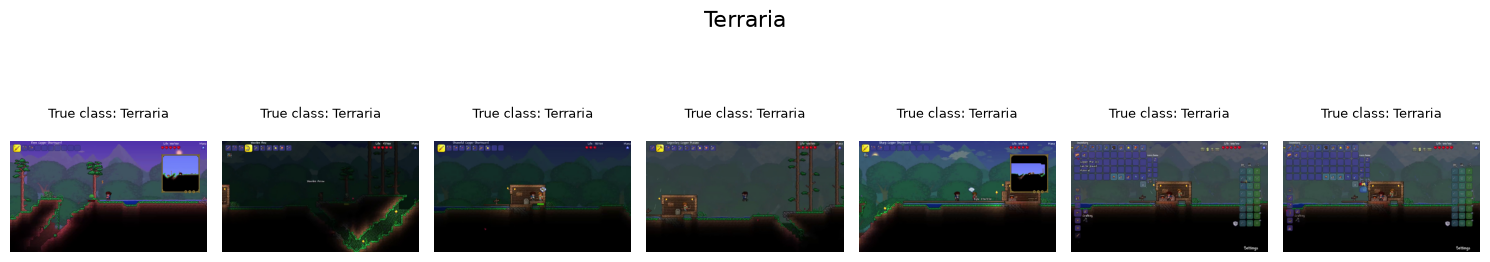

In [ ]:
N_NEIGHBORS = 7

y_train = f['labels_train'][:]

for i, (label, centers) in enumerate(centroids.items()):
    mask = y_train == i

    X_class = f['embeddings_train'][mask]
    indices_class = np.where(mask)[0]

    paths_class = f['paths_train'].asstr()[indices_class]

    nn = NearestNeighbors(
        n_neighbors=N_NEIGHBORS,
        metric='cosine',
        n_jobs=-1
    )

    nn.fit(X_class)

    distances, indices = nn.kneighbors(centers)

    n_centers = len(centers)

    fig, axes = plt.subplots(
        n_centers,
        N_NEIGHBORS,
        figsize=(15, 3.5 * n_centers),
        squeeze=False
    )

    fig.suptitle(label, fontsize=16)

    for c in range(n_centers):

        for j in range(N_NEIGHBORS):

            local_idx = indices[c, j]
            global_idx = indices_class[local_idx]

            img = Image.open(paths_class[local_idx]).convert('RGB')

            axes[c, j].imshow(img)
            axes[c, j].axis('off')

            true_label = labels[y_train[global_idx]]

            axes[c, j].set_title(
                f'True class: {true_label}\n',
                fontsize=9
            )

    plt.tight_layout()

In [100]:
def predict_by_centroids(embeddings, centroids, metric='cosine'):
    distances = []
    for label in label2num_classes.keys():
        centers = centroids[label]
        class_distances = pairwise_distances(
            embeddings,
            centers,
            metric=metric
        )

        distances.append(class_distances.min(axis=1))

    distances = np.stack(distances, axis=1)
    return np.argmin(distances, axis=1)

Predicted class: Apex Legends


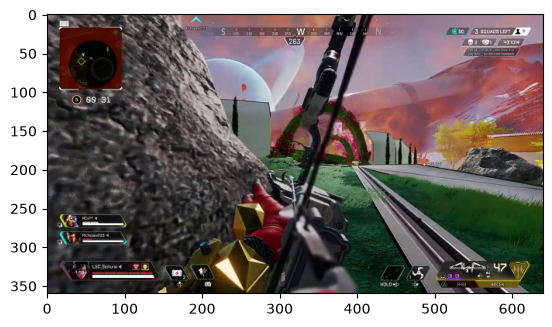

In [106]:
id = 1
pred = predict_by_centroids_proba(
    f['embeddings_val'][id][None],
    centroids
)

plt.imshow(Image.open(f['paths_val'][id]).convert('RGB'))

print('Predicted class:', labels[pred[0]])

([<matplotlib.axis.YTick at 0x7f6679330a50>,
 [Text(0, 0, 'Among Us'),
  Text(0, 1, 'Apex Legends'),
  Text(0, 2, 'Fortnite'),
  Text(0, 3, 'Forza Horizon'),
  Text(0, 4, 'Free Fire'),
  Text(0, 5, 'Genshin Impact'),
  Text(0, 6, 'God of War'),
  Text(0, 7, 'Minecraft'),
  Text(0, 8, 'Roblox'),
  Text(0, 9, 'Terraria')])

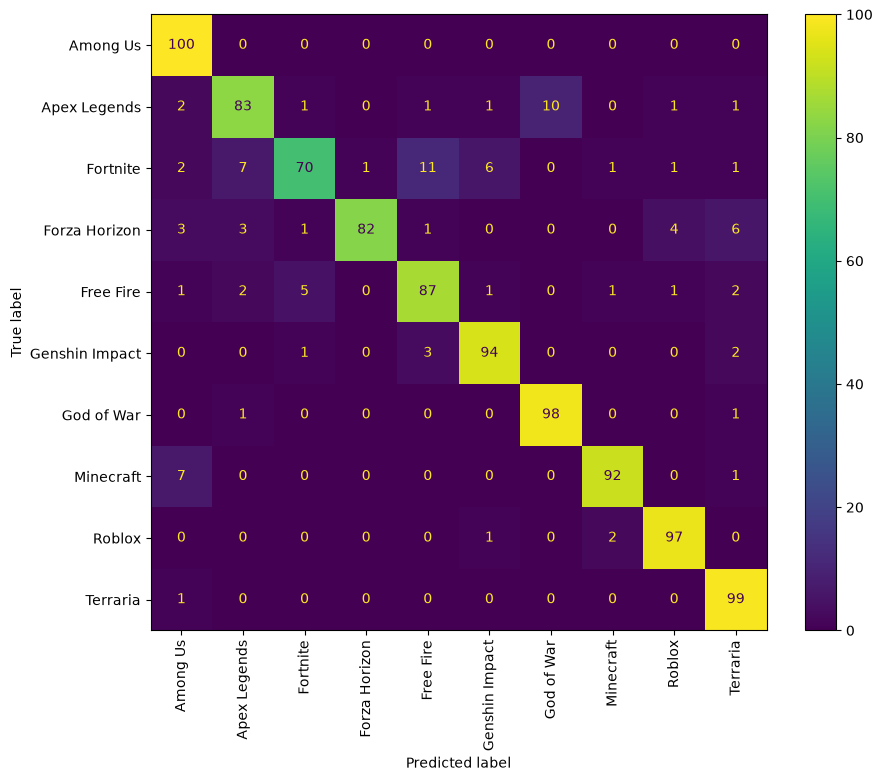

In [108]:
X_val = f['embeddings_val'][:]
y_val = f['labels_val'][:]

y_pred = predict_by_centroids(X_val, centroids, metric='cosine')

conf_mat = confusion_matrix(
    y_val,
    y_pred,
    labels=np.arange(len(labels))
)

disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, values_format='d')

plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
